Download data

In [1]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
!ls

processed.cleveland.data  sample_data


Load data

In [2]:
import pandas as pd

columns = ["age","sex","cp","trestbps","chol","fbs","restecg",
           "thalach","exang","oldpeak","slope","ca","thal","num"]

df = pd.read_csv("processed.cleveland.data", header=None, names=columns, na_values="?")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Missing values

In [3]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Make the target 0/1

In [4]:
# num: 0 = no disease, 1-4 = disease of different severity
# 0 = no disease, 1 = disease
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns="num")

df["target"].value_counts()

,count
target,
0,164
1,139


Fill the missing values

In [5]:
for col in ["ca", "thal"]:
    df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop_duplicates()
print("Missing values left:", df.isna().sum().sum())
print("Shape after cleaning:", df.shape)

Missing values left: 0
Shape after cleaning: (303, 14)


Encode the category columns

In [6]:
df_encoded = pd.get_dummies(df, columns=["cp", "thal", "restecg", "slope"], dtype=int)

print("Shape after encoding:", df_encoded.shape)
df_encoded.head()

Shape after encoding: (303, 23)


,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,...,cp_4.0,thal_3.0,thal_6.0,thal_7.0,restecg_0.0,restecg_1.0,restecg_2.0,slope_1.0,slope_2.0,slope_3.0
0,63.0,1.0,145.0,233.0,1.0,150.0,0.0,2.3,0.0,0,...,0,0,1,0,0,0,1,0,0,1
1,67.0,1.0,160.0,286.0,0.0,108.0,1.0,1.5,3.0,1,...,1,1,0,0,0,0,1,0,1,0
2,67.0,1.0,120.0,229.0,0.0,129.0,1.0,2.6,2.0,1,...,1,0,0,1,0,0,1,0,1,0
3,37.0,1.0,130.0,250.0,0.0,187.0,0.0,3.5,0.0,0,...,0,1,0,0,1,0,0,0,0,1
4,41.0,0.0,130.0,204.0,0.0,172.0,0.0,1.4,0.0,0,...,0,1,0,0,0,0,1,1,0,0


Save the cleaned dataset

In [7]:
df.to_csv("heart_clean.csv", index=False)
print("Saved heart_clean.csv")

Saved heart_clean.csv


Setup for charts

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("figures", exist_ok=True)   # folder to keep all chart images
sns.set_theme(style="whitegrid")

Class balance chart

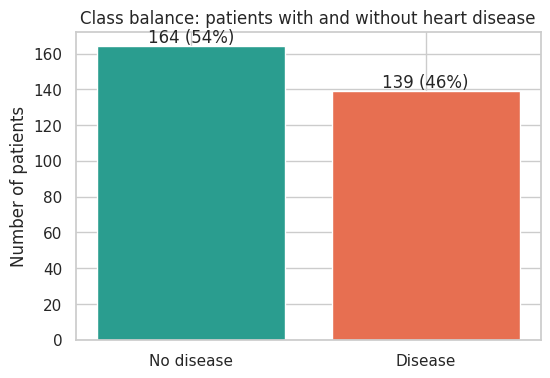

In [9]:
counts = df["target"].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(["No disease", "Disease"], counts.values, color=["#2a9d8f", "#e76f51"])
for bar, n in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, n, f"{n} ({n/counts.sum():.0%})", ha="center", va="bottom")
plt.title("Class balance: patients with and without heart disease")
plt.ylabel("Number of patients")
plt.savefig("figures/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

Histograms

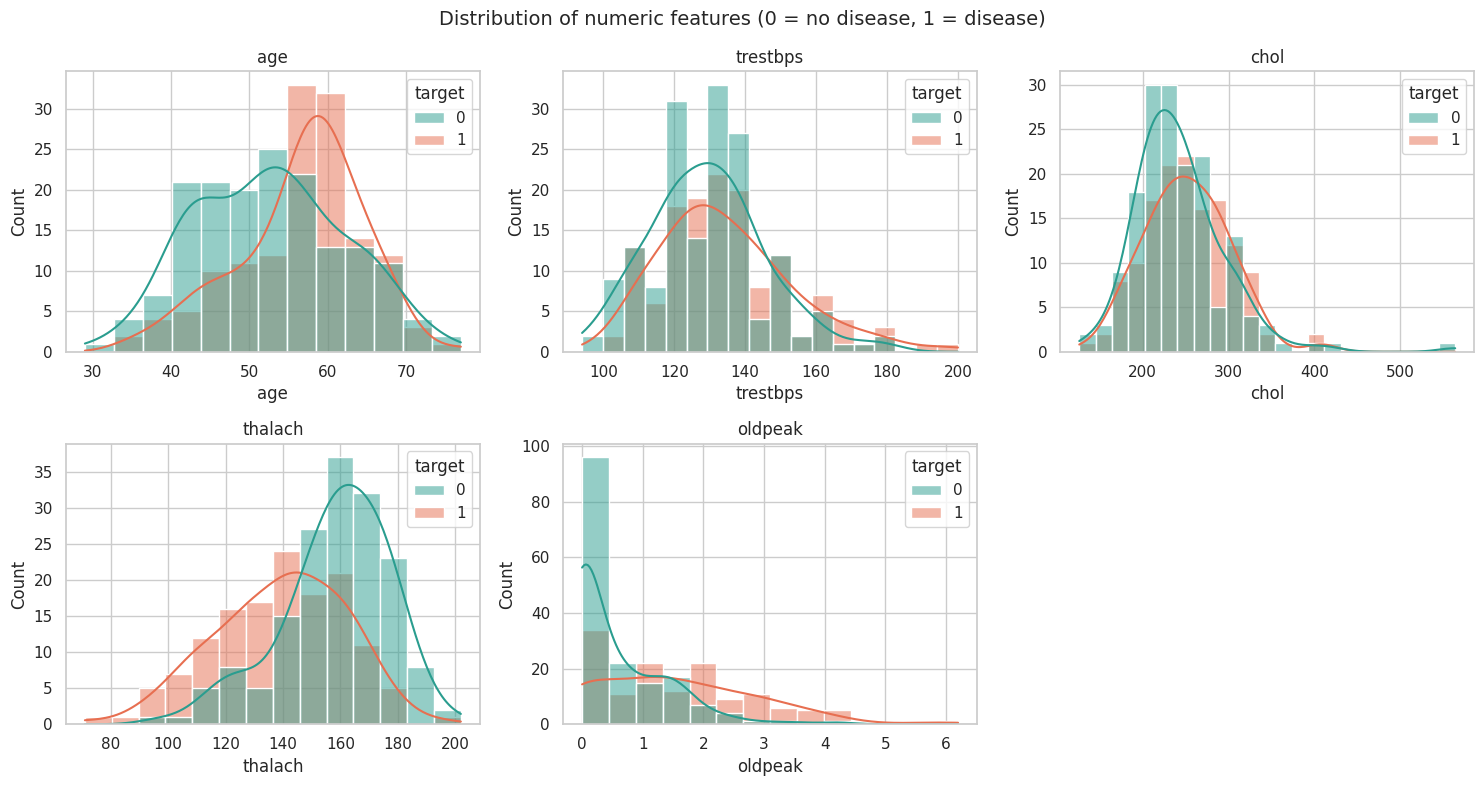

In [10]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax, palette=["#2a9d8f", "#e76f51"])
    ax.set_title(col)
axes.flat[-1].axis("off")       # hide the empty 6th box
plt.suptitle("Distribution of numeric features (0 = no disease, 1 = disease)", fontsize=14)
plt.tight_layout()
plt.savefig("figures/histograms.png", dpi=150, bbox_inches="tight")
plt.show()

Correlation heatmap

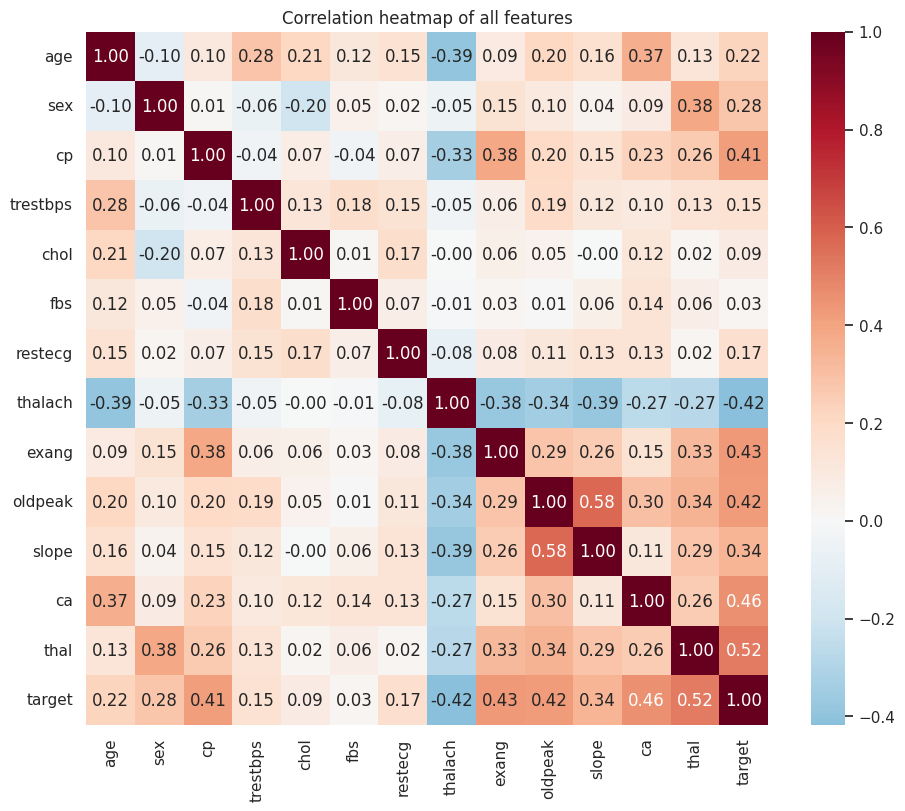

In [11]:
plt.figure(figsize=(11, 9))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation heatmap of all features")
plt.savefig("figures/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

Ranking features by correlation with disease

In [12]:
df.corr()["target"].drop("target").sort_values(ascending=False)

,target
thal,0.522057
ca,0.460033
exang,0.431894
oldpeak,0.424510
cp,0.414446
slope,0.339213
sex,0.276816
age,0.223120
restecg,0.169202
trestbps,0.150825


Disease rate by category

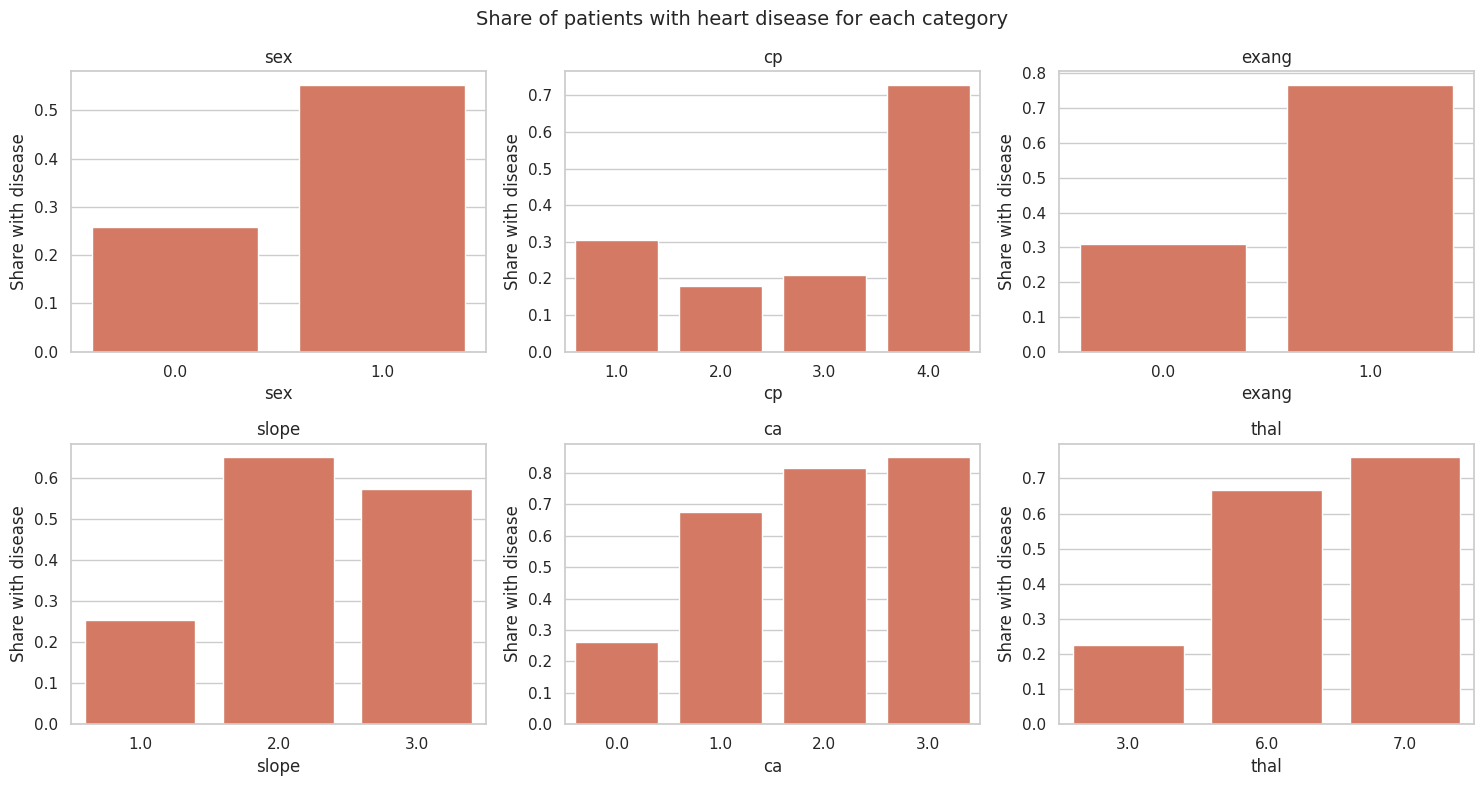

In [13]:
cat_cols = ["sex", "cp", "exang", "slope", "ca", "thal"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cat_cols):
    sns.barplot(data=df, x=col, y="target", ax=ax, color="#e76f51", errorbar=None)
    ax.set_ylabel("Share with disease")
    ax.set_title(col)
plt.suptitle("Share of patients with heart disease for each category", fontsize=14)
plt.tight_layout()
plt.savefig("figures/disease_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

Download all charts

In [14]:
!zip -r figures.zip figures
from google.colab import files
files.download("figures.zip")

  adding: figures/ (stored 0%)
  adding: figures/class_balance.png (deflated 15%)
  adding: figures/histograms.png (deflated 7%)
  adding: figures/correlation_heatmap.png (deflated 5%)
  adding: figures/disease_rate_by_category.png (deflated 26%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## EDA Findings

- The dataset has 303 patients and 13 features. Only 6 values were missing
  (4 in ca, 2 in thal); these were filled with the most common value.
- The original target (0-4) was converted to binary: 0 = no disease, 1 = disease.
- Classes are fairly balanced: 164 without disease (54%) and 139 with disease (46%),
  so accuracy is a reasonable metric, but precision, recall and ROC-AUC are also reported.
- Features most related to heart disease: thal (0.52), ca (0.46), exang (0.43),
  oldpeak (0.42) and cp (0.41).
- Maximum heart rate (thalach) has a negative correlation (-0.42): disease patients
  reach a lower peak heart rate during exercise.
- Cholesterol (0.09) and fasting blood sugar (0.03) are only weakly related to the
  target on their own.
- cp, thal, restecg and slope are category codes, so they were one-hot encoded;
  numeric features have different scales and will be standardised before modelling.